In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [6]:


df = pd.read_csv("../data/Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (7043, 21)

Column Names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn   

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Churn"].value_counts())

print("\nTarget Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Records:
0

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)


df = df.drop(columns=["customerID"])


X = df.drop(columns=["Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0})


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [10]:
eda_df = X_train.copy()
eda_df["Churn"] = y_train

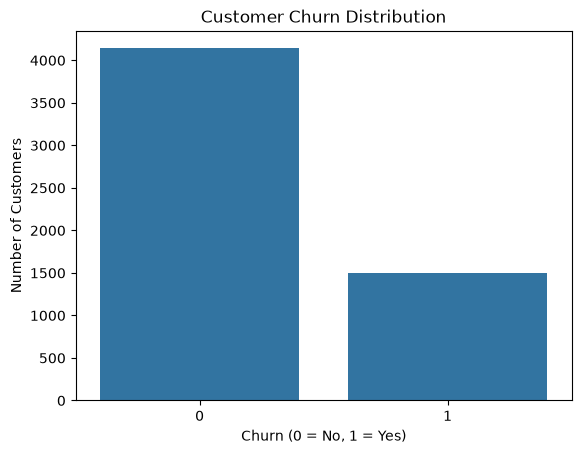

In [11]:
sns.countplot(data=eda_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

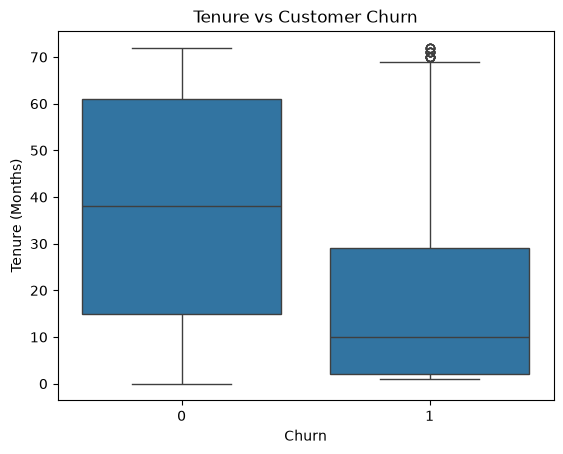

In [12]:
sns.boxplot(data=eda_df, x="Churn", y="tenure")

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

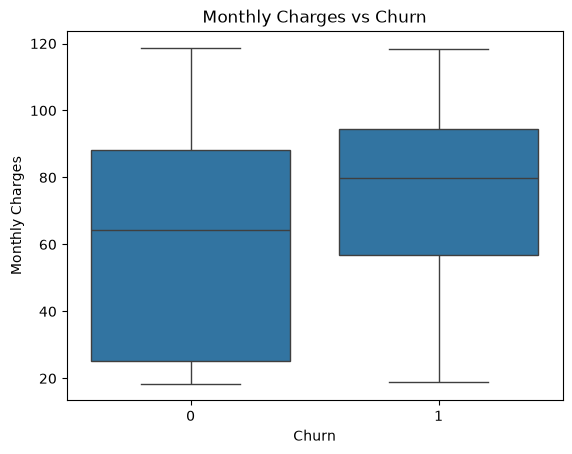

In [13]:
sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

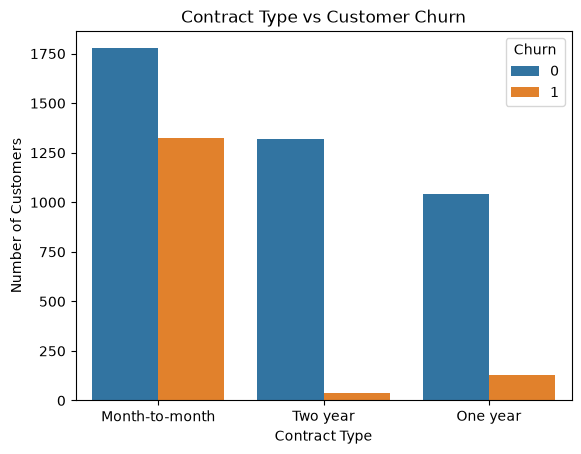

In [14]:
sns.countplot(
    data=eda_df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

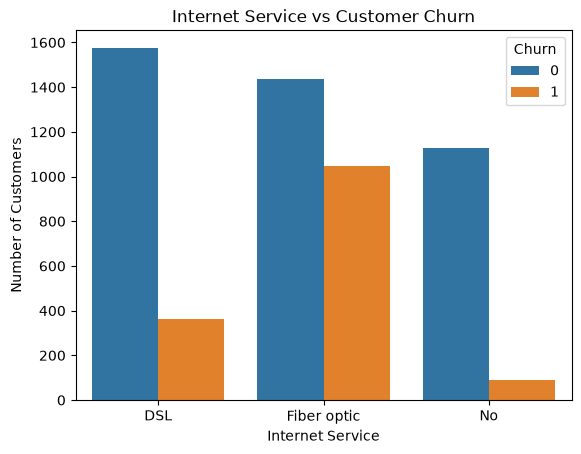

In [15]:
sns.countplot(
    data=eda_df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()


def create_features(data):

    data = data.copy()

    
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Medium", "Long", "Very Long"]
    )

    
    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    data["total_services"] = (
        data[service_columns] == "Yes"
    ).sum(axis=1)

    data["avg_spend_per_month"] = np.where(
        data["tenure"] > 0,
        data["TotalCharges"] / data["tenure"],
        data["MonthlyCharges"]
    )

    data["has_family"] = (
        (data["Partner"] == "Yes") |
        (data["Dependents"] == "Yes")
    ).astype(int)

    data["is_long_contract"] = (
        data["Contract"].isin(["One year", "Two year"])
    ).astype(int)

    return data


X_train_fe = create_features(X_train_fe)
X_test_fe = create_features(X_test_fe)

print("Feature engineering completed!")

print("Original number of training features:", X_train.shape[1])
print("New number of training features:", X_train_fe.shape[1])

display(X_train_fe.head())

Feature engineering completed!
Original number of training features: 19
New number of training features: 24


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,total_services,avg_spend_per_month,has_family,is_long_contract
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Month-to-month,No,Electronic check,49.20,1701.65,Long,3,48.618571,0,0
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,Month-to-month,No,Mailed check,75.10,1151.55,Medium,2,76.770000,1,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,Two year,No,Mailed check,40.55,590.35,Medium,3,45.411538,1,1
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Two year,Yes,Credit card (automatic),73.50,1905.70,Long,5,73.296154,1,1
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,Month-to-month,No,Electronic check,44.55,44.55,New,1,44.550000,1,0
